In [1]:
from qiskit import QuantumCircuit
from qiskit_addon_cutting import cut_gates, generate_cutting_experiments, reconstruct_expectation_values
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import matplotlib.pyplot as plt
import numpy as np

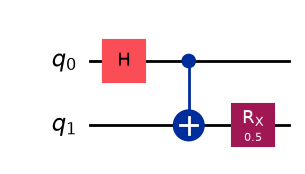

In [2]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.rx(0.5, 1)
display(qc.draw('mpl'))

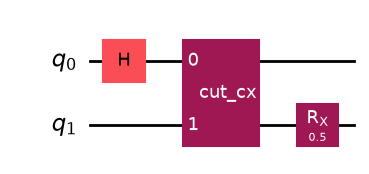

Circuit cut successfully!


In [3]:
cut_circuit, cut_mapping = cut_gates(qc, gate_ids=[1])
display(cut_circuit.draw('mpl'))
print("Circuit cut successfully!")

In [4]:
observable = SparsePauliOp.from_list([("ZZ", 1.0)])

subexperiments, coefficients = generate_cutting_experiments(
    circuits=cut_circuit,
    observables=observable.paulis,
    num_samples=np.inf
)

print("Number of sub-experiments:", len(subexperiments))
for i, (c, _) in enumerate(coefficients):
    print(i, c)

Number of sub-experiments: 6
0 0.5
1 0.5
2 0.5
3 -0.5
4 0.5
5 -0.5


In [5]:
backend = AerSimulator()
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_subexperiments = pm.run(subexperiments)

print("Ready:", len(isa_subexperiments), "circuits")

Ready: 6 circuits


In [6]:
sampler = SamplerV2()
results = sampler.run(isa_subexperiments, shots=4096).result()

print("Done:", len(results), "results")

Done: 6 results


In [7]:
cut_value = reconstruct_expectation_values(results, coefficients, observable.paulis)
cut_value = np.dot(cut_value, observable.coeffs).real

print("Cut result:", cut_value)

Cut result: 0.87548828125


In [8]:
exact_value = Statevector(qc).expectation_value(observable).real

print("Cut result:  ", cut_value)
print("Exact result:", exact_value)
print("Error:       ", abs(cut_value - exact_value))

Cut result:   0.87548828125
Exact result: 0.8775825618903725
Error:        0.0020942806403725367
